# Flight Fare Prediction

**Objective:** In this project I analyze the Flight Fare dataset (Task 1) and build a model that predicts the ticket price for a journey (Task 2).

**Dataset:** `Flight_Fare.xlsx` — 10,683 domestic Indian flight records (March to June 2019) with airline, route, timing, duration, stops and price.

**Approach:** We clean the data, engineer features, explore it, then compare several regression models inside a leak-free pipeline. All error metrics are reported in rupees (₹).

| Block | Content |
| --- | --- |
| 1 | Setup and Data Loading |
| 2 | Data Understanding and Quality Checks |
| 3 | Data Cleaning |
| 4 | Feature Engineering |
| 5 | Exploratory Data Analysis (with EDA Summary) |
| 6 | Train/Test Split and Preprocessing |
| 7 | Baseline Models |
| 8 | Hyperparameter Tuning |
| 9 | Final Model Comparison and Diagnostics |
| 10 | Model Export and Prediction Function |
| 11 | Report on Challenges Faced |
| 12 | Model Comparison Report |

**How to run:** Upload `Flight_Fare.xlsx` to the Colab session (`/content/`) or place it next to this notebook, then run all cells from top to bottom.

## Block 1 — Setup and Data Loading

### 1.1 Import Libraries

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

### 1.2 Configure Global Settings

In [2]:
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

### 1.3 Load the Dataset

In [3]:
DATA_PATHS = [
    Path("/content/Flight_Fare.xlsx"),
    Path("Flight_Fare.xlsx"),
    Path("Flight_Fare/Flight_Fare.xlsx"),
]
data_path = next((path for path in DATA_PATHS if path.exists()), None)
if data_path is None:
    raise FileNotFoundError("Flight_Fare.xlsx was not found. Upload it to /content/ or the notebook folder.")

raw_df = pd.read_excel(data_path)
print(f"Loaded {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns from {data_path}")
raw_df.head()

Loaded 10,683 rows and 11 columns from Flight_Fare.xlsx


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


### Block 1 Summary

- The libraries cover data handling, visualization, preprocessing, modeling and evaluation.
- A fixed random seed (`RANDOM_STATE = 42`) makes every result reproducible.
- We keep the raw data in `raw_df` and never modify it; all cleaning is applied to a copy.

## Block 2 — Data Understanding and Quality Checks

### 2.1 Structure and Data Types

In [4]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 918.2 KB


In [5]:
raw_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Airline,10683,12,Jet Airways,3849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date_of_Journey,10683,44,18/05/2019,504,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source,10683,5,Delhi,4537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,10683,6,Cochin,4537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Route,10682,128,DEL → BOM → COK,2376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dep_Time,10683,222,18:55,233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Arrival_Time,10683,1343,19:00,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration,10683,368,2h 50m,550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total_Stops,10682,5,1 stop,5625,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Additional_Info,10683,10,No info,8345,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.2 Missing Values

In [6]:
missing_counts = raw_df.isna().sum()
print(missing_counts[missing_counts > 0].to_string())
print()
print("Row with missing values:")
raw_df[raw_df.isna().any(axis=1)]

Route          1
Total_Stops    1

Row with missing values:


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


### 2.3 Duplicate Records

In [7]:
duplicate_count = raw_df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count} ({duplicate_count / len(raw_df):.1%} of the data)")

Duplicate rows: 220 (2.1% of the data)


### 2.4 Categorical Value Counts

In [8]:
for column in ["Airline", "Source", "Destination", "Total_Stops", "Additional_Info"]:
    print(f"--- {column} ---")
    print(raw_df[column].value_counts(dropna=False).to_string())
    print()

--- Airline ---
Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1

--- Source ---
Source
Delhi       4537
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381

--- Destination ---
Destination
Cochin       4537
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381

--- Total_Stops ---
Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
NaN            1
4 stops        1

--- Additional_Info ---
Additional_Info
No info                         8345
In-flight 

### Block 2 Summary

- The data has 10,683 rows and 11 columns; only `Price` is numeric, so we need to parse the time and duration fields.
- `Route` and `Total_Stops` each have one missing value, and both fall in the same row.
- There are 220 exact duplicate rows (about 2%).
- We found these label problems: `No info` vs `No Info`, `Delhi` vs `New Delhi`, and several airline and info categories with fewer than 15 rows.

## Block 3 — Data Cleaning

### 3.1 Remove Duplicates and Missing Values

I drop the single row with missing values. Filling it with the most common route would invent a flight that was never recorded.

In [9]:
df = raw_df.drop_duplicates().dropna().reset_index(drop=True)
print(f"Rows before cleaning: {len(raw_df):,}")
print(f"Rows after cleaning : {len(df):,}  ({len(raw_df) - len(df)} removed)")

Rows before cleaning: 10,683
Rows after cleaning : 10,462  (221 removed)


### 3.2 Standardize Category Labels

We apply four fixes:

- Trim stray whitespace in the categorical text columns.
- Merge `No info` into `No Info`.
- Merge `New Delhi` into `Delhi`; both labels refer to the same city.
- Group very rare airline and additional-info categories (fewer than 5 rows) into `Other`.

In [10]:
RARE_THRESHOLD = 5

RARE_AIRLINES = set(df["Airline"].value_counts().loc[lambda counts: counts < RARE_THRESHOLD].index)
RARE_INFO = set(
    df["Additional_Info"].str.strip().replace({"No info": "No Info"})
    .value_counts().loc[lambda counts: counts < RARE_THRESHOLD].index
)
print("Rare airlines grouped into 'Other':", sorted(RARE_AIRLINES))
print("Rare info labels grouped into 'Other':", sorted(RARE_INFO))


def standardize_labels(data):
    """Return a copy of `data` with consistent category labels."""
    out = data.copy()
    for column in ["Airline", "Source", "Destination", "Route", "Total_Stops", "Additional_Info"]:
        out[column] = out[column].str.strip()
    out["Additional_Info"] = out["Additional_Info"].replace({"No info": "No Info"})
    out["Destination"] = out["Destination"].replace({"New Delhi": "Delhi"})
    out["Airline"] = out["Airline"].where(~out["Airline"].isin(RARE_AIRLINES), "Other")
    out["Additional_Info"] = out["Additional_Info"].where(~out["Additional_Info"].isin(RARE_INFO), "Other")
    return out


df = standardize_labels(df)

Rare airlines grouped into 'Other': ['Trujet', 'Vistara Premium economy']
Rare info labels grouped into 'Other': ['1 Short layover', '2 Long layover', 'Business class', 'Red-eye flight']


### 3.3 Validate the Cleaned Data

In [11]:
print(f"Missing values remaining: {df.isna().sum().sum()}")
print()
print(df["Airline"].value_counts().to_string())
print()
print(df["Additional_Info"].value_counts().to_string())
print()
print(df["Destination"].value_counts().to_string())

Missing values remaining: 0

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Other                                   4

Additional_Info
No Info                         8185
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Other                              7
Change airports                    7

Destination
Cochin       4345
Banglore     2860
Delhi        2179
Hyderabad     697
Kolkata       381


### Block 3 Summary

- We removed 221 records: 220 duplicates and 1 row with missing values. The cleaned data has 10,462 rows and no missing values.
- Merging inconsistent labels means the model no longer treats one city or one category as two.
- Grouping rare categories into `Other` avoids columns with only one or two non-zero rows.

## Block 4 — Feature Engineering

### 4.1 Define the Feature-Engineering Function

We reuse the same function later to prepare new journeys for prediction, so training and prediction always use identical logic.

In [12]:
STOPS_MAP = {"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}


def duration_to_minutes(text):
    """Convert a duration such as '2h 50m' or '19h' into minutes."""
    hours, minutes = 0, 0
    for part in text.split():
        if part.endswith("h"):
            hours = int(part[:-1])
        elif part.endswith("m"):
            minutes = int(part[:-1])
    return hours * 60 + minutes


def engineer_features(data):
    """Create numeric date, time, duration and stop features from the raw text columns."""
    out = data.copy()

    journey = pd.to_datetime(out["Date_of_Journey"], dayfirst=True)
    out["Journey_Day"] = journey.dt.day
    out["Journey_Month"] = journey.dt.month
    out["Journey_Weekday"] = journey.dt.dayofweek  # Monday = 0, Sunday = 6
    out["Is_Weekend"] = (out["Journey_Weekday"] >= 5).astype(int)

    departure = pd.to_datetime(out["Dep_Time"], format="%H:%M")
    out["Dep_Hour"] = departure.dt.hour
    out["Dep_Minute"] = departure.dt.minute

    arrival = pd.to_datetime(out["Arrival_Time"].str.split().str[0], format="%H:%M")
    out["Arrival_Hour"] = arrival.dt.hour
    out["Arrival_Minute"] = arrival.dt.minute

    out["Duration_Minutes"] = out["Duration"].apply(duration_to_minutes)
    out["Arrival_Day_Offset"] = (departure.dt.hour * 60 + departure.dt.minute + out["Duration_Minutes"]) // 1440
    out["Total_Stops"] = out["Total_Stops"].map(STOPS_MAP)

    out["Dep_Period"] = pd.cut(
        out["Dep_Hour"], bins=[-1, 5, 11, 17, 23],
        labels=["Night (00-05)", "Morning (06-11)", "Afternoon (12-17)", "Evening (18-23)"],
    )
    return out

### 4.2 Apply the Function

In [13]:
features_df = engineer_features(df)
features_df[
    ["Date_of_Journey", "Journey_Day", "Journey_Month", "Journey_Weekday", "Is_Weekend",
     "Dep_Time", "Dep_Hour", "Arrival_Time", "Arrival_Hour", "Duration", "Duration_Minutes",
     "Arrival_Day_Offset", "Total_Stops"]
].head()

,Date_of_Journey,Journey_Day,Journey_Month,Journey_Weekday,Is_Weekend,Dep_Time,Dep_Hour,Arrival_Time,Arrival_Hour,Duration,Duration_Minutes,Arrival_Day_Offset,Total_Stops
0,24/03/2019,24,3,6,1,22:20,22,01:10 22 Mar,1,2h 50m,170,1,0
1,1/05/2019,1,5,2,0,05:50,5,13:15,13,7h 25m,445,0,2
2,9/06/2019,9,6,6,1,09:25,9,04:25 10 Jun,4,19h,1140,1,2
3,12/05/2019,12,5,6,1,18:05,18,23:30,23,5h 25m,325,0,1
4,01/03/2019,1,3,4,0,16:50,16,21:35,21,4h 45m,285,0,1


### 4.3 Sanity Checks on the New Features

In [14]:
route_stopovers = features_df["Route"].str.count("→") - 1  # Each arrow is one flight leg; stopovers = legs - 1
print(f"Unmapped stop labels: {features_df['Total_Stops'].isna().sum()}")
print(f"Rows where Total_Stops matches the number of stopovers in Route: {(route_stopovers == features_df['Total_Stops']).mean():.1%}")

text_next_day = features_df["Arrival_Time"].str.split().str.len() > 1
print(f"Rows where the next-day flag agrees with the raw arrival text: {(text_next_day == (features_df['Arrival_Day_Offset'] > 0)).mean():.1%}")

print(f"Shortest flight: {features_df['Duration_Minutes'].min()} minutes | longest flight: {features_df['Duration_Minutes'].max() / 60:.1f} hours")
print(f"Journey dates: {pd.to_datetime(df['Date_of_Journey'], dayfirst=True).min().date()} to {pd.to_datetime(df['Date_of_Journey'], dayfirst=True).max().date()}")

Unmapped stop labels: 0
Rows where Total_Stops matches the number of stopovers in Route: 100.0%
Rows where the next-day flag agrees with the raw arrival text: 100.0%
Shortest flight: 5 minutes | longest flight: 47.7 hours
Journey dates: 2019-03-01 to 2019-06-27


### 4.4 Define the Final Feature Set

The numeric versions replace the original text columns. We do not create `Journey_Year` because every record is from 2019.

In [15]:
TARGET = "Price"
NUMERIC_FEATURES = [
    "Total_Stops", "Duration_Minutes", "Journey_Day", "Journey_Month", "Journey_Weekday",
    "Is_Weekend", "Dep_Hour", "Dep_Minute", "Arrival_Hour", "Arrival_Minute", "Arrival_Day_Offset",
]
CATEGORICAL_FEATURES = ["Airline", "Source", "Destination", "Route", "Additional_Info"]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

model_df = features_df[ALL_FEATURES + [TARGET, "Dep_Period"]].copy()
print(f"Modeling table: {model_df.shape[0]:,} rows, {len(ALL_FEATURES)} features")
model_df.dtypes.to_frame("dtype").T

Modeling table: 10,462 rows, 16 features


,Total_Stops,Duration_Minutes,Journey_Day,Journey_Month,Journey_Weekday,Is_Weekend,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Arrival_Day_Offset,Airline,Source,Destination,Route,Additional_Info,Price,Dep_Period
dtype,int64,int64,int32,int32,int32,int64,int32,int32,int32,int32,int64,str,str,str,str,str,int64,category


### Block 4 Summary

- Dates become day, month, weekday and weekend features; times become hour and minute features.
- We convert `Duration` to minutes and `Total_Stops` to a number, and an `Arrival_Day_Offset` feature captures overnight flights.
- The stop count agrees with the number of stopovers in `Route` for almost every row, so `Total_Stops` is reliable.
- The final feature set has 11 numeric and 5 categorical features. `Dep_Period` is kept only for EDA.

## Block 5 — Exploratory Data Analysis

### 5.1 Target Distribution

count    10462
mean      9027
std       4625
min       1759
25%       5224
50%       8266
75%      12345
max      79512

Skewness of Price           : 1.86
Skewness of log(1 + Price)  : -0.23


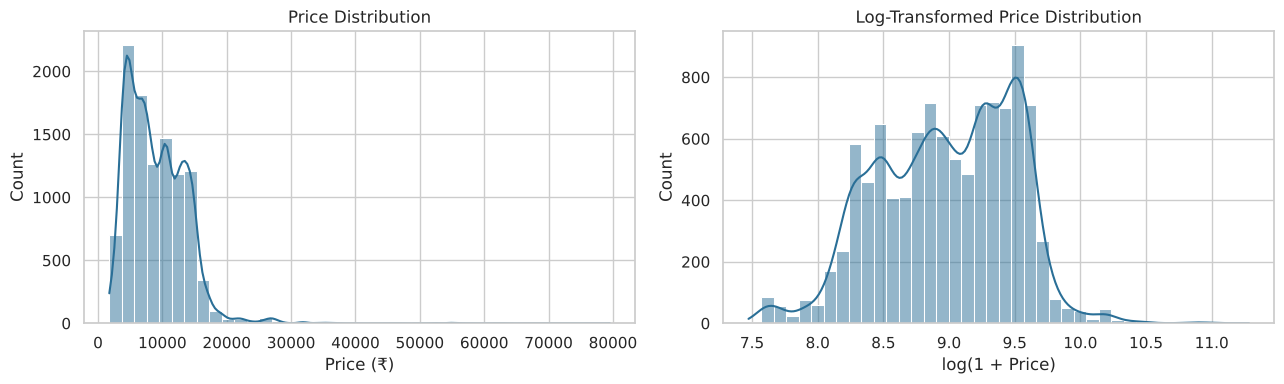

In [16]:
print(model_df[TARGET].describe().round(0).astype(int).to_string())
print()
print(f"Skewness of Price           : {model_df[TARGET].skew():.2f}")
print(f"Skewness of log(1 + Price)  : {np.log1p(model_df[TARGET]).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(model_df[TARGET], bins=40, kde=True, ax=axes[0], color="#2a6f97")
axes[0].set_title("Price Distribution")
axes[0].set_xlabel("Price (₹)")
sns.histplot(np.log1p(model_df[TARGET]), bins=40, kde=True, ax=axes[1], color="#2a6f97")
axes[1].set_title("Log-Transformed Price Distribution")
axes[1].set_xlabel("log(1 + Price)")
plt.tight_layout()
plt.show()

### 5.2 Price by Airline

                                   Flights  Median_Price
Airline                                                 
SpiceJet                               815          3873
IndiGo                                2043          5000
GoAir                                  194          5135
Air Asia                               319          5162
Other                                    4          7547
Vistara                                478          7980
Air India                             1694          9316
Multiple carriers                     1196         10197
Jet Airways                           3700         11134
Multiple carriers Premium economy       13         11269
Jet Airways Business                     6         54747


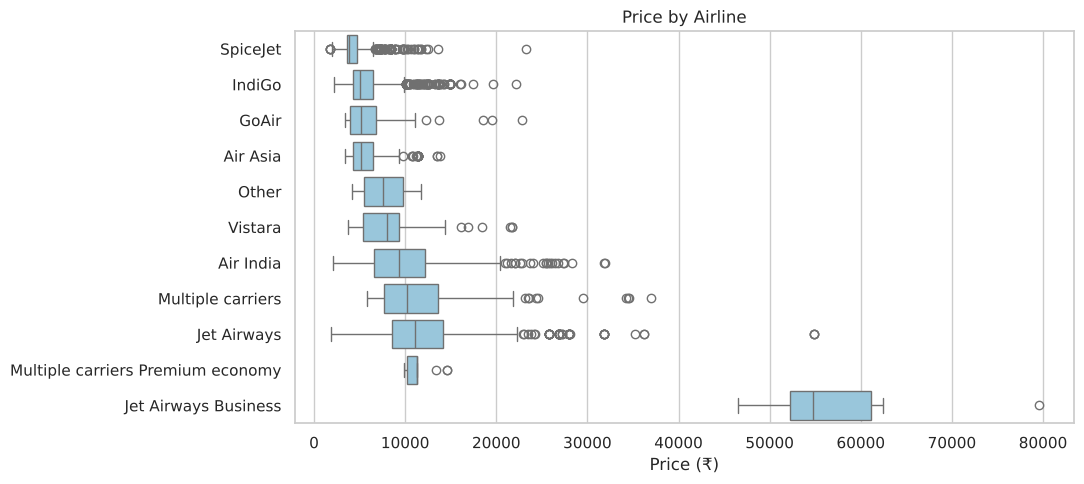

In [17]:
airline_stats = (
    model_df.groupby("Airline")[TARGET].agg(Flights="count", Median_Price="median")
    .sort_values("Median_Price")
)
airline_stats["Median_Price"] = airline_stats["Median_Price"].round(0).astype(int)
print(airline_stats.to_string())

plt.figure(figsize=(11, 5))
sns.boxplot(data=model_df, y="Airline", x=TARGET, order=airline_stats.index, color="#8ecae6")
plt.title("Price by Airline")
plt.xlabel("Price (₹)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 5.3 Price by Stops and Duration

             Flights  Median_Price
Total_Stops                       
0               3475          4667
1               5625         10262
2               1318         12723
3                 43         13007
4                  1         17686


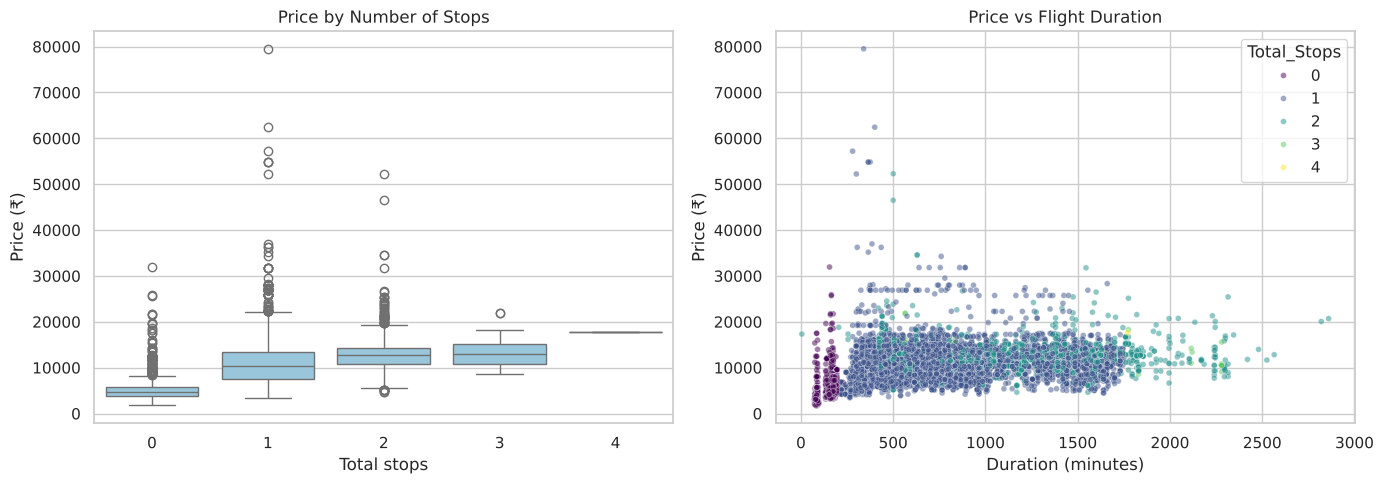

In [18]:
stops_stats = model_df.groupby("Total_Stops")[TARGET].agg(Flights="count", Median_Price="median")
stops_stats["Median_Price"] = stops_stats["Median_Price"].round(0).astype(int)
print(stops_stats.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=model_df, x="Total_Stops", y=TARGET, ax=axes[0], color="#8ecae6")
axes[0].set_title("Price by Number of Stops")
axes[0].set_xlabel("Total stops")
axes[0].set_ylabel("Price (₹)")

sns.scatterplot(
    data=model_df, x="Duration_Minutes", y=TARGET, hue="Total_Stops",
    palette="viridis", alpha=0.5, s=18, ax=axes[1],
)
axes[1].set_title("Price vs Flight Duration")
axes[1].set_xlabel("Duration (minutes)")
axes[1].set_ylabel("Price (₹)")
plt.tight_layout()
plt.show()

### 5.4 Price by Route

                    Flights  Median_Price
Journey                                  
Mumbai → Hyderabad      697          3342
Chennai → Kolkata       381          3850
Banglore → Delhi       2179          6121
Kolkata → Banglore     2860          9345
Delhi → Cochin         4345         10262


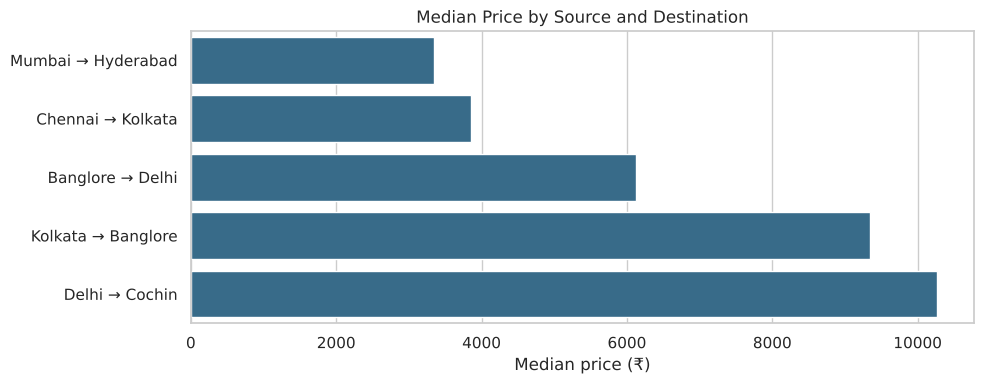

In [19]:
journey_pairs = (model_df["Source"] + " → " + model_df["Destination"]).rename("Journey")
pair_stats = (
    model_df.assign(Journey=journey_pairs).groupby("Journey")[TARGET]
    .agg(Flights="count", Median_Price="median").sort_values("Median_Price")
)
plt.figure(figsize=(10, 4))
sns.barplot(x=pair_stats["Median_Price"], y=pair_stats.index, color="#2a6f97")
plt.title("Median Price by Source and Destination")
plt.xlabel("Median price (₹)")
plt.ylabel("")
plt.tight_layout()
plt.show()

pair_stats["Median_Price"] = pair_stats["Median_Price"].round(0).astype(int)
print(pair_stats.to_string())

### 5.5 Time and Calendar Effects

Journey_Month
March    9769
April    5073
May      8662
June     8510

Journey_Weekday
Monday       7480
Tuesday      8452
Wednesday    8529
Thursday     8266
Friday       7229
Saturday     8146
Sunday       9555

Dep_Period
Night (00-05)        7352
Morning (06-11)      8266
Afternoon (12-17)    8372
Evening (18-23)      8452



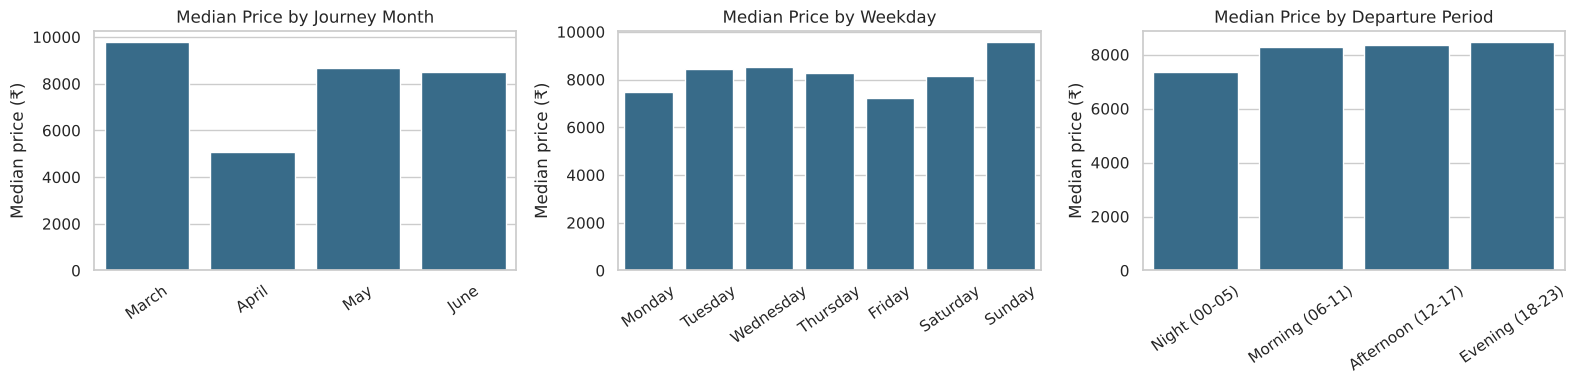

In [20]:
month_names = {3: "March", 4: "April", 5: "May", 6: "June"}
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

by_month = model_df.groupby("Journey_Month")[TARGET].median().rename(index=month_names)
by_weekday = model_df.groupby("Journey_Weekday")[TARGET].median().rename(index=dict(enumerate(weekday_names)))
by_period = model_df.groupby("Dep_Period", observed=True)[TARGET].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, series, title in zip(
    axes, [by_month, by_weekday, by_period],
    ["Median Price by Journey Month", "Median Price by Weekday", "Median Price by Departure Period"],
):
    sns.barplot(x=series.index.astype(str), y=series.values, ax=axis, color="#2a6f97")
    axis.set_title(title)
    axis.set_xlabel("")
    axis.set_ylabel("Median price (₹)")
    axis.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

for series in (by_month, by_weekday, by_period):
    print(series.round(0).astype(int).rename("Median price (₹)").to_string())
    print()

### 5.6 Additional Information

In [21]:
info_stats = (
    model_df.groupby("Additional_Info")[TARGET].agg(Flights="count", Median_Price="median")
    .sort_values("Median_Price")
)
info_stats["Median_Price"] = info_stats["Median_Price"].round(0).astype(int)
info_stats

,Flights,Median_Price
Additional_Info,,
No check-in baggage included,318,3841
No Info,8185,7893
In-flight meal not included,1926,10262
Change airports,7,15119
1 Long layover,19,25735
Other,7,28097


### 5.7 Correlation Analysis

Correlation with Price:
Total_Stops           0.60
Duration_Minutes      0.50
Arrival_Day_Offset    0.34
Journey_Weekday       0.06
Arrival_Hour          0.03
Is_Weekend            0.02
Dep_Hour              0.01
Dep_Minute           -0.02
Arrival_Minute       -0.09
Journey_Month        -0.11
Journey_Day          -0.16


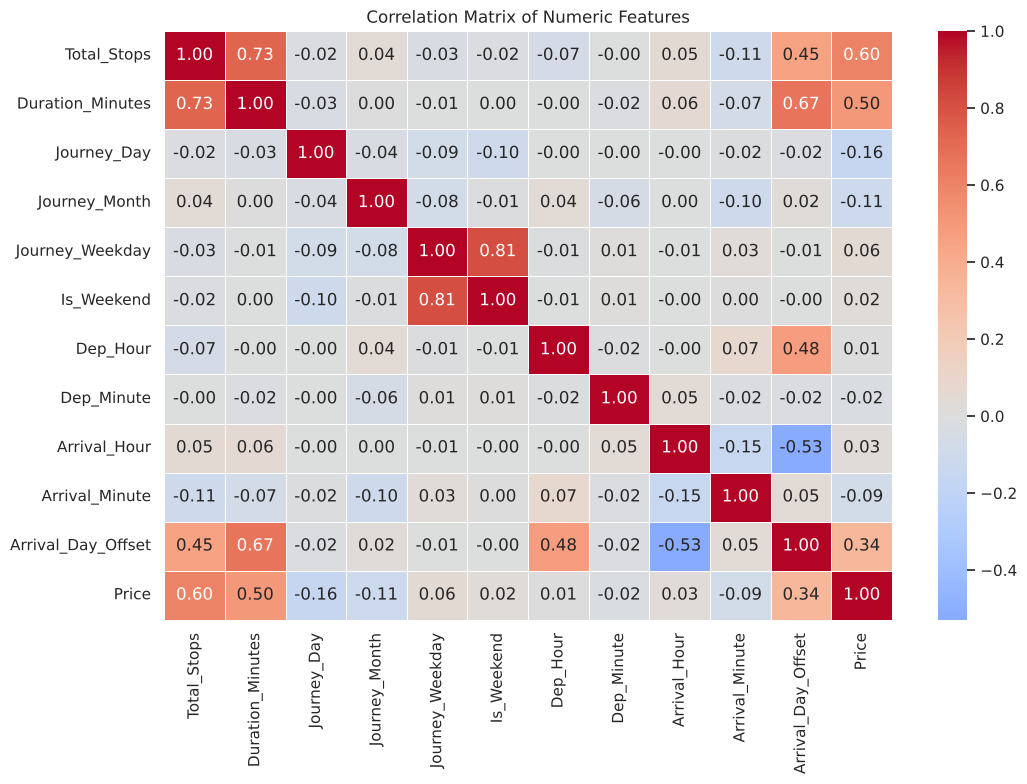

In [22]:
correlation = model_df[NUMERIC_FEATURES + [TARGET]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

print("Correlation with Price:")
print(correlation[TARGET].drop(TARGET).sort_values(ascending=False).round(2).to_string())

### 5.8 EDA Summary

**Dataset snapshot**

- 10,462 flights after cleaning, covering 40 journey dates from 1 March to 27 June 2019, 5 source cities, 5 destinations and 128 distinct routes.
- The median fare is ₹8,266 (mean ₹9,027), ranging from ₹1,759 to ₹79,512.

**Key findings**

| Factor | What the data shows |
| --- | --- |
| Price distribution | Right-skewed (skewness 1.86). Only 8 fares exceed ₹50,000. A log transform reduces the skewness to −0.23. |
| Airline | The strongest categorical driver. Budget carriers have the lowest median fares (SpiceJet ₹3,873, IndiGo ₹5,000, GoAir ₹5,135, Air Asia ₹5,162). Vistara (₹7,980) sits in the middle; Air India (₹9,316) and Jet Airways (₹11,134) are higher. Jet Airways Business is far above all others (₹54,747, only 6 flights). |
| Stops and duration | Median fare rises from ₹4,667 (non-stop) to ₹10,262 (1 stop) and ₹12,723 (2 stops). `Total_Stops` (r = 0.60) and `Duration_Minutes` (r = 0.50) have the strongest correlations with price. |
| Route | Short routes are cheapest (Mumbai → Hyderabad ₹3,342; Chennai → Kolkata ₹3,850) and Delhi → Cochin is the most expensive (₹10,262). Route effects overlap with airline and stops. |
| Calendar | April is the cheapest month (₹5,073) and March the most expensive (₹9,769). Sunday has the highest weekday median (₹9,555) and Friday the lowest (₹7,229). |
| Departure time | A small effect: night departures are slightly cheaper (₹7,352) than other periods (₹8,266 to ₹8,452). |
| Additional info | `No check-in baggage included` (₹3,841) occurs only on SpiceJet, and `In-flight meal not included` (₹10,262) occurs almost entirely on Jet Airways, so this field mostly mirrors the airline. |
| Outliers | 94 fares lie above the IQR upper fence. They are genuine premium or long multi-stop fares, so we keep them. |

**Implications for modeling**

- We train on `log(1 + Price)` to handle the skew, and report errors in rupees.
- We use models that capture interactions (airline × stops × duration); a purely linear model will miss them.
- I treat the calendar patterns as descriptive only: months and routes have different flight mixes (for example, April has 1,078 flights versus 3,395 in May), so part of the month effect is a mix effect.
- Stops, duration and next-day arrival are correlated with each other (r = 0.73 between stops and duration), which tree-based models handle well.

## Block 6 — Train/Test Split and Preprocessing

### 6.1 Split the Data

We split the data **before** any fitting, so the holdout set stays completely unseen. The target stays in rupees; we apply the log transform inside the model pipeline (Section 6.2).

In [23]:
X = model_df[ALL_FEATURES]
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
print(f"Training rows: {len(X_train):,} | Holdout rows: {len(X_test):,}")

Training rows: 7,846 | Holdout rows: 2,616


### 6.2 Build the Preprocessing Pipeline

- We one-hot encode the categorical features, so no false order is imposed on airlines or routes. Categories unseen during training are ignored safely.
- We standardize numeric features only for Linear Regression; tree-based models do not need scaling.
- `TransformedTargetRegressor` trains on `log(1 + Price)` and converts predictions back to rupees, so every metric is reported in ₹.
- We fit every transformer on training data only (inside each cross-validation fold), which prevents data leakage.

In [24]:
def make_model(estimator, scale_numeric=False):
    """Wrap an estimator in preprocessing and a log-price target transform."""
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ("numeric", numeric_step, NUMERIC_FEATURES),
    ])
    pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)

### 6.3 Define the Evaluation Helper

We score each model with 5-fold cross-validation on the training set and once on the holdout set. Metrics: R², MAE and RMSE (the last two in ₹), plus MAPE. We record the train R² to detect overfitting.

In [25]:
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

DISPLAY_ROUNDING = {
    "CV R²": 3, "CV MAE (₹)": 0, "CV RMSE (₹)": 0, "Holdout R²": 3, "Holdout MAE (₹)": 0,
    "Holdout RMSE (₹)": 0, "Holdout MAPE (%)": 1, "Train R²": 3, "Time (s)": 1,
}

results = []        # One row of metrics per model
fitted_models = {}  # Fitted pipelines, keyed by model name
best_params = {}    # Tuned hyperparameters, keyed by model name


def evaluate_model(label, model, stage):
    """Cross-validate on the training set, refit, and score on the holdout set."""
    start = time.perf_counter()
    cv_scores = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - start

    holdout_pred = model.predict(X_test)
    row = {
        "Model": label,
        "Stage": stage,
        "CV R²": cv_scores["test_r2"].mean(),
        "CV MAE (₹)": -cv_scores["test_mae"].mean(),
        "CV RMSE (₹)": -cv_scores["test_rmse"].mean(),
        "Holdout R²": r2_score(y_test, holdout_pred),
        "Holdout MAE (₹)": mean_absolute_error(y_test, holdout_pred),
        "Holdout RMSE (₹)": np.sqrt(mean_squared_error(y_test, holdout_pred)),
        "Holdout MAPE (%)": mean_absolute_percentage_error(y_test, holdout_pred) * 100,
        "Train R²": r2_score(y_train, model.predict(X_train)),
        "Time (s)": seconds,
    }
    results.append(row)
    fitted_models[label] = model
    return pd.DataFrame([row]).set_index("Model").drop(columns="Stage").round(DISPLAY_ROUNDING)

### Block 6 Summary

- A 75/25 split gives 7,846 training rows and 2,616 holdout rows.
- Preprocessing, the log-price transform and the model live in one pipeline, so nothing from the test data influences training.
- The helper reports cross-validated and holdout metrics in rupees for every model, which makes the comparison fair.

## Block 7 — Baseline Models

### 7.1 Linear Regression

In [26]:
evaluate_model("Linear Regression", make_model(LinearRegression(), scale_numeric=True), "Baseline")

,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Linear Regression,0.745,1454.0,2320.0,0.743,1435.0,2342.0,16.5,0.761,1.6


### 7.2 Decision Tree

In [27]:
evaluate_model("Decision Tree", make_model(DecisionTreeRegressor(random_state=RANDOM_STATE)), "Baseline")

,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Decision Tree,0.812,751.0,2003.0,0.86,716.0,1732.0,8.1,0.997,0.3


### 7.3 Random Forest

In [28]:
evaluate_model(
    "Random Forest",
    make_model(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE)),
    "Baseline",
)

,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Random Forest,0.869,659.0,1658.0,0.91,602.0,1384.0,6.8,0.974,24.5


### 7.4 Gradient Boosting (Histogram-Based)

In [29]:
evaluate_model(
    "Gradient Boosting",
    make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    "Baseline",
)

,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Gradient Boosting,0.854,872.0,1753.0,0.871,857.0,1662.0,9.6,0.889,5.0


### 7.5 Baseline Results

In [30]:
pd.DataFrame(results).set_index("Model").drop(columns="Stage").round(DISPLAY_ROUNDING)

,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Linear Regression,0.745,1454.0,2320.0,0.743,1435.0,2342.0,16.5,0.761,1.6
Decision Tree,0.812,751.0,2003.0,0.860,716.0,1732.0,8.1,0.997,0.3
Random Forest,0.869,659.0,1658.0,0.910,602.0,1384.0,6.8,0.974,24.5
Gradient Boosting,0.854,872.0,1753.0,0.871,857.0,1662.0,9.6,0.889,5.0


### Block 7 Summary

- We trained four model families with default settings.
- The baseline table (7.5) shows how much each model improves on the linear baseline before any tuning.

## Block 8 — Hyperparameter Tuning

### 8.1 Tuning Helper

A randomized search with 3-fold cross-validation optimizes MAE in rupees, using the training data only. I treat the cross-validation score of a tuned model as slightly optimistic because the same data guided the search, so the holdout score is the more honest measure.

In [31]:
def tune_and_evaluate(label, estimator, param_distributions, n_iter, scale_numeric=False):
    """Run a randomized search, then evaluate the best model with the standard helper."""
    prefix = "regressor__model__"
    search = RandomizedSearchCV(
        make_model(estimator, scale_numeric),
        {prefix + name: values for name, values in param_distributions.items()},
        n_iter=n_iter,
        cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
        random_state=RANDOM_STATE,
        refit=True,
    )
    start = time.perf_counter()
    search.fit(X_train, y_train)
    print(f"{label}: search finished in {time.perf_counter() - start:.0f}s | best 3-fold MAE = ₹{-search.best_score_:,.0f}")
    best_params[label] = {name.replace(prefix, ""): value for name, value in search.best_params_.items()}
    print("Best parameters:", best_params[label])
    return evaluate_model(f"{label} (Tuned)", search.best_estimator_, "Tuned")

### 8.2 Decision Tree

In [32]:
tune_and_evaluate(
    "Decision Tree",
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    {
        "max_depth": [8, 12, 16, 20, None],
        "min_samples_leaf": [1, 2, 4, 8],
        "min_samples_split": [2, 5, 10],
        "max_features": [None, 0.7],
    },
    n_iter=15,
)

Decision Tree: search finished in 1s | best 3-fold MAE = ₹752
Best parameters: {'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 20}


,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Decision Tree (Tuned),0.825,755.0,1931.0,0.88,693.0,1598.0,7.8,0.966,0.3


### 8.3 Random Forest

In [33]:
tune_and_evaluate(
    "Random Forest",
    RandomForestRegressor(random_state=RANDOM_STATE),
    {
        "n_estimators": [200, 300],
        "max_depth": [None, 25],
        "min_samples_leaf": [1, 2, 3],
        "min_samples_split": [2, 5],
        "max_features": [0.5, 0.7, 1.0],
    },
    n_iter=12,
)

Random Forest: search finished in 74s | best 3-fold MAE = ₹707
Best parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': None}


,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Random Forest (Tuned),0.871,659.0,1646.0,0.91,609.0,1390.0,6.9,0.975,18.7


### 8.4 Gradient Boosting (Histogram-Based)

In [34]:
tune_and_evaluate(
    "Gradient Boosting",
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    {
        "learning_rate": [0.03, 0.05, 0.1],
        "max_iter": [300, 500, 800],
        "max_leaf_nodes": [15, 31, 63],
        "max_depth": [None, 6, 10],
        "min_samples_leaf": [10, 20, 40],
        "l2_regularization": [0, 0.1, 1.0],
    },
    n_iter=15,
)

Gradient Boosting: search finished in 114s | best 3-fold MAE = ₹734
Best parameters: {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'max_iter': 800, 'max_depth': 10, 'learning_rate': 0.03, 'l2_regularization': 0}


,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Gradient Boosting (Tuned),0.879,694.0,1591.0,0.907,663.0,1410.0,7.3,0.962,45.4


### 8.5 Optional: XGBoost and LightGBM

These two libraries are available in Google Colab. If they are installed, we tune them and add them to the comparison automatically; otherwise this step is skipped without affecting the rest of the notebook. Locally, install them with `pip install xgboost lightgbm`.

In [35]:
try:
    from xgboost import XGBRegressor

    tune_and_evaluate(
        "XGBoost",
        XGBRegressor(tree_method="hist", n_jobs=1, random_state=RANDOM_STATE, verbosity=0),
        {
            "n_estimators": [300, 500, 800],
            "learning_rate": [0.03, 0.05, 0.1],
            "max_depth": [4, 6, 8],
            "min_child_weight": [1, 3, 5],
            "subsample": [0.7, 0.8, 0.9],
            "colsample_bytree": [0.6, 0.8, 1.0],
            "reg_lambda": [0.5, 1.0, 2.0],
        },
        n_iter=15,
    )
except ImportError:
    print("XGBoost is not installed, so it was skipped.")

XGBoost is not installed, so it was skipped.


In [36]:
try:
    from lightgbm import LGBMRegressor

    tune_and_evaluate(
        "LightGBM",
        LGBMRegressor(n_jobs=1, random_state=RANDOM_STATE, verbose=-1),
        {
            "n_estimators": [300, 500, 800],
            "learning_rate": [0.03, 0.05, 0.1],
            "num_leaves": [15, 31, 63],
            "min_child_samples": [10, 20, 40],
            "subsample": [0.7, 0.8, 0.9],
            "colsample_bytree": [0.6, 0.8, 1.0],
            "reg_lambda": [0, 0.5, 1.0],
        },
        n_iter=15,
    )
except ImportError:
    print("LightGBM is not installed, so it was skipped.")

LightGBM is not installed, so it was skipped.


### Block 8 Summary

- We tuned each model family with a randomized search that minimizes MAE in rupees.
- We score tuned models with the same cross-validation and holdout procedure as the baselines.
- XGBoost and LightGBM join the comparison automatically when their libraries are installed.

## Block 9 — Final Model Comparison and Diagnostics

### 9.1 Results Table

We rank models by cross-validated MAE. We choose the winner on cross-validation, not on the holdout set, so the holdout score remains an unbiased estimate.

In [37]:
results_df = pd.DataFrame(results).sort_values("CV MAE (₹)").reset_index(drop=True)
results_df.drop(columns="Stage").set_index("Model").round(DISPLAY_ROUNDING)

,CV R²,CV MAE (₹),CV RMSE (₹),Holdout R²,Holdout MAE (₹),Holdout RMSE (₹),Holdout MAPE (%),Train R²,Time (s)
Model,,,,,,,,,
Random Forest,0.869,659.0,1658.0,0.910,602.0,1384.0,6.8,0.974,24.5
Random Forest (Tuned),0.871,659.0,1646.0,0.910,609.0,1390.0,6.9,0.975,18.7
Gradient Boosting (Tuned),0.879,694.0,1591.0,0.907,663.0,1410.0,7.3,0.962,45.4
Decision Tree,0.812,751.0,2003.0,0.860,716.0,1732.0,8.1,0.997,0.3
Decision Tree (Tuned),0.825,755.0,1931.0,0.880,693.0,1598.0,7.8,0.966,0.3
Gradient Boosting,0.854,872.0,1753.0,0.871,857.0,1662.0,9.6,0.889,5.0
Linear Regression,0.745,1454.0,2320.0,0.743,1435.0,2342.0,16.5,0.761,1.6


### 9.2 Visual Comparison

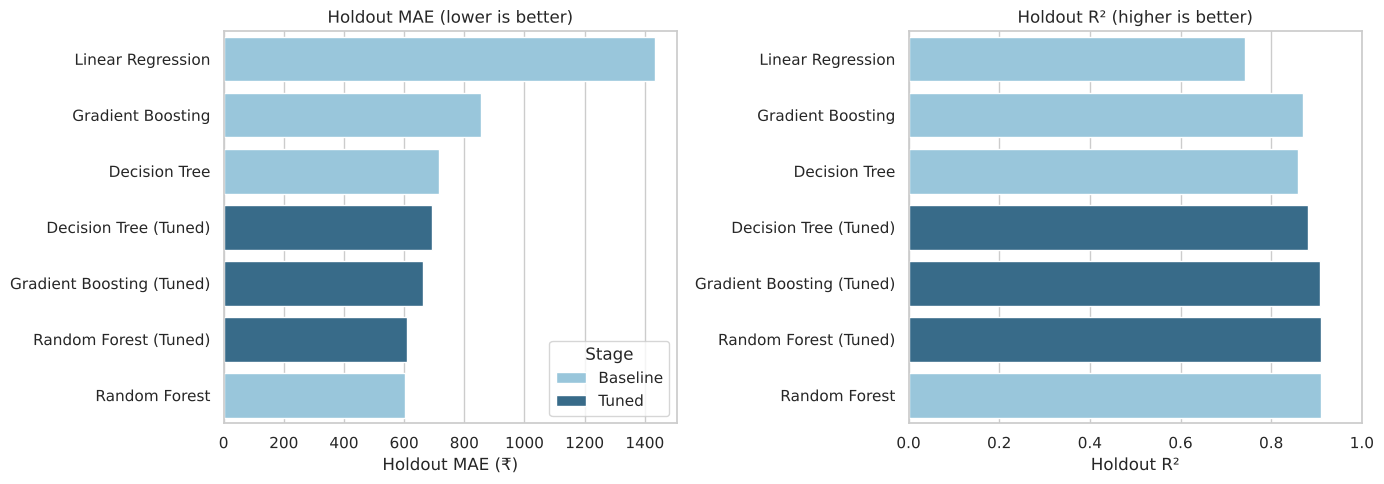

In [38]:
plot_df = results_df.sort_values("Holdout MAE (₹)", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=plot_df, y="Model", x="Holdout MAE (₹)", hue="Stage", dodge=False, ax=axes[0], palette={"Baseline": "#8ecae6", "Tuned": "#2a6f97"})
axes[0].set_title("Holdout MAE (lower is better)")
axes[0].set_ylabel("")

sns.barplot(data=plot_df, y="Model", x="Holdout R²", hue="Stage", dodge=False, ax=axes[1], palette={"Baseline": "#8ecae6", "Tuned": "#2a6f97"})
axes[1].set_title("Holdout R² (higher is better)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 1)
axes[1].get_legend().remove()
plt.tight_layout()
plt.show()

### 9.3 Select the Best Model

In [39]:
best_label = results_df.iloc[0]["Model"]
best_model = fitted_models[best_label]
best_row = results_df.iloc[0]

print(f"Best model (lowest cross-validated MAE): {best_label}")
print(f"Holdout R²   : {best_row['Holdout R²']:.3f}")
print(f"Holdout MAE  : ₹{best_row['Holdout MAE (₹)']:,.0f}")
print(f"Holdout RMSE : ₹{best_row['Holdout RMSE (₹)']:,.0f}")
print(f"Holdout MAPE : {best_row['Holdout MAPE (%)']:.1f}%")

Best model (lowest cross-validated MAE): Random Forest
Holdout R²   : 0.910
Holdout MAE  : ₹602
Holdout RMSE : ₹1,384
Holdout MAPE : 6.8%


### 9.4 Prediction Quality

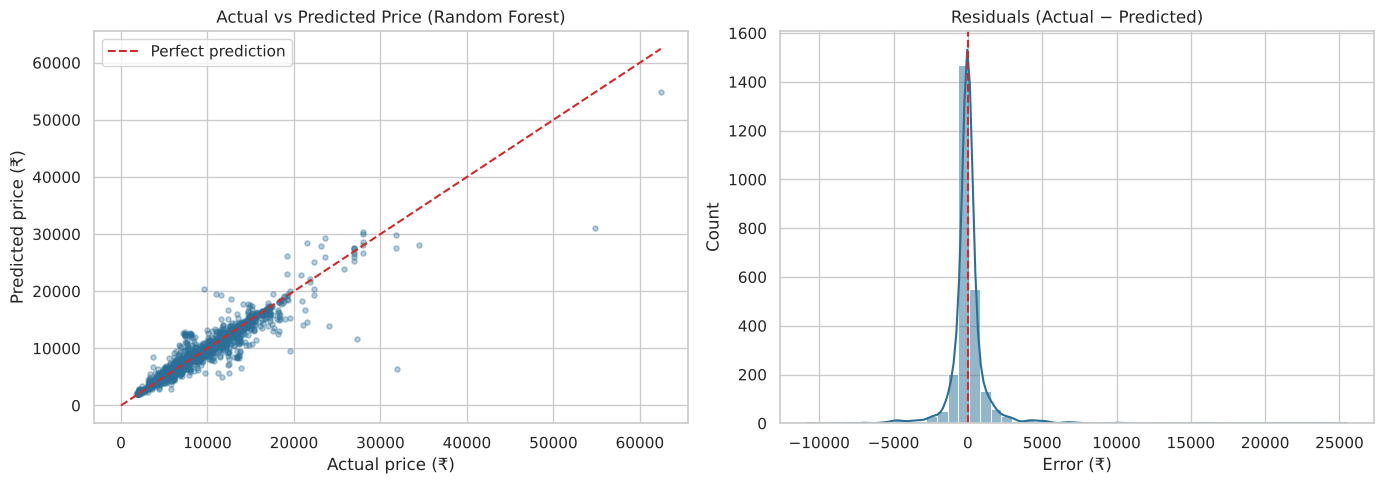

In [40]:
holdout_pred = best_model.predict(X_test)
residuals = y_test - holdout_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, holdout_pred, alpha=0.35, s=14, color="#2a6f97")
limit = max(y_test.max(), holdout_pred.max())
axes[0].plot([0, limit], [0, limit], color="#d62828", linestyle="--", label="Perfect prediction")
axes[0].set_title(f"Actual vs Predicted Price ({best_label})")
axes[0].set_xlabel("Actual price (₹)")
axes[0].set_ylabel("Predicted price (₹)")
axes[0].legend()

sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color="#2a6f97")
axes[1].axvline(0, color="#d62828", linestyle="--")
axes[1].set_title("Residuals (Actual − Predicted)")
axes[1].set_xlabel("Error (₹)")
plt.tight_layout()
plt.show()

### 9.5 Error by Price Band

This shows where the model is strong and where it struggles.

In [41]:
bands = pd.qcut(y_test, 4, labels=["Lowest 25%", "Lower-middle 25%", "Upper-middle 25%", "Highest 25%"])
band_report = pd.DataFrame({
    "Flights": y_test.groupby(bands, observed=True).size(),
    "Actual Price Range (₹)": y_test.groupby(bands, observed=True).apply(lambda s: f"{s.min():,.0f} - {s.max():,.0f}"),
    "MAE (₹)": (residuals.abs()).groupby(bands, observed=True).mean(),
    "MAPE (%)": ((residuals.abs() / y_test) * 100).groupby(bands, observed=True).mean(),
})
band_report = band_report.round({"MAE (₹)": 0, "MAPE (%)": 1})
band_report

,Flights,Actual Price Range (₹),MAE (₹),MAPE (%)
Price,,,,
Lowest 25%,655,"1,759 - 5,192",247.0,6.4
Lower-middle 25%,653,"5,195 - 8,085",622.0,9.1
Upper-middle 25%,661,"8,098 - 12,192",599.0,5.9
Highest 25%,647,"12,199 - 62,427",942.0,5.6


### 9.6 Feature Importance

Permutation importance measures how much the holdout MAE worsens when one input feature is shuffled. It works on the original features, so the results are easy to interpret.

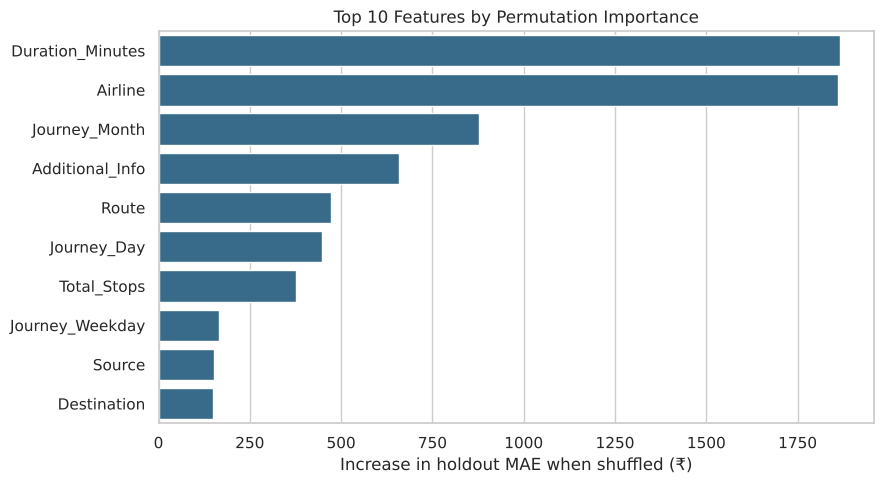

,Feature,MAE Increase (₹)
1,Duration_Minutes,1865.8
11,Airline,1861.2
3,Journey_Month,877.3
15,Additional_Info,658.1
14,Route,473.4
2,Journey_Day,448.0
0,Total_Stops,377.3
4,Journey_Weekday,165.4
12,Source,151.9
13,Destination,150.1


In [42]:
importance = permutation_importance(
    best_model, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_df = (
    pd.DataFrame({"Feature": X_test.columns, "MAE Increase (₹)": importance.importances_mean})
    .sort_values("MAE Increase (₹)", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df.head(10), y="Feature", x="MAE Increase (₹)", color="#2a6f97")
plt.title("Top 10 Features by Permutation Importance")
plt.xlabel("Increase in holdout MAE when shuffled (₹)")
plt.ylabel("")
plt.tight_layout()
plt.show()

importance_df.head(10).round(1)

### Block 9 Summary

- We selected the best model on cross-validated MAE and then confirmed it on the untouched holdout set.
- The prediction plots, price-band table and feature importances show how the model behaves, not only how it scores.
- See Block 12 for the written model comparison and recommendation.

## Block 10 — Model Export and Prediction Function

### 10.1 Save the Model

The saved file contains the full pipeline (encoding, log transform and model), so it can predict directly from raw feature values.

In [43]:
MODEL_PATH = Path("flight_fare_model.joblib")
joblib.dump(best_model, MODEL_PATH, compress=3)
print(f"Saved '{best_label}' to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

Saved 'Random Forest' to flight_fare_model.joblib (20.0 MB)


### 10.2 Prediction Function

The function takes a journey in the same format as the original dataset and returns the predicted fare in rupees.

In [44]:
def predict_fare(model, airline, source, destination, route, total_stops,
                 additional_info, journey_date, dep_time, arrival_time, duration):
    """Predict the fare in ₹ for one journey.

    Formats follow the original data: journey_date 'dd/mm/yyyy', times 'HH:MM',
    duration '2h 50m', total_stops 'non-stop' / '1 stop' / '2 stops'.
    """
    journey = pd.DataFrame([{
        "Airline": airline, "Date_of_Journey": journey_date, "Source": source,
        "Destination": destination, "Route": route, "Dep_Time": dep_time,
        "Arrival_Time": arrival_time, "Duration": duration,
        "Total_Stops": total_stops, "Additional_Info": additional_info,
    }])
    features = engineer_features(standardize_labels(journey))[ALL_FEATURES]
    return float(model.predict(features)[0])

### 10.3 Example Predictions

We test two airlines on the same Delhi → Cochin journey, plus a non-stop Bangalore → Delhi flight. The spelling "Banglore" follows the dataset.

In [45]:
examples = [
    dict(airline="Jet Airways", source="Delhi", destination="Cochin", route="DEL → BOM → COK",
         total_stops="1 stop", additional_info="No Info", journey_date="15/05/2019",
         dep_time="09:00", arrival_time="19:15", duration="10h 15m"),
    dict(airline="IndiGo", source="Delhi", destination="Cochin", route="DEL → BOM → COK",
         total_stops="1 stop", additional_info="No Info", journey_date="15/05/2019",
         dep_time="09:00", arrival_time="19:15", duration="10h 15m"),
    dict(airline="IndiGo", source="Banglore", destination="Delhi", route="BLR → DEL",
         total_stops="non-stop", additional_info="No Info", journey_date="15/05/2019",
         dep_time="06:00", arrival_time="08:45", duration="2h 45m"),
]
for example in examples:
    fare = predict_fare(best_model, **example)
    print(f"{example['airline']:<12} {example['route']:<18} {example['total_stops']:<9} -> predicted fare: ₹{fare:,.0f}")

Jet Airways  DEL → BOM → COK    1 stop    -> predicted fare: ₹15,660
IndiGo       DEL → BOM → COK    1 stop    -> predicted fare: ₹7,244
IndiGo       BLR → DEL          non-stop  -> predicted fare: ₹4,112


### Block 10 Summary

- We save the best pipeline as `flight_fare_model.joblib`; it can be reloaded with `joblib.load`.
- `predict_fare` reuses the same cleaning and feature-engineering functions as training, so predictions are consistent.
- I consider the model reliable only for journeys similar to the training data (March to June 2019, the routes listed in the dataset).

## Block 11 — Report on Challenges Faced

### 11.1 Data Challenges and Solutions

| # | Challenge | Evidence in the data | Technique used | Reason |
| --- | --- | --- | --- | --- |
| 1 | Duplicate records | 220 exact duplicate rows (about 2%) | `drop_duplicates()` | Duplicates inflate the sample size and can leak identical rows into both train and test sets, which overstates accuracy. |
| 2 | Missing values | One row with `Route` and `Total_Stops` both missing | Dropped the row | Imputing the most common route would create a flight that never existed; losing one row in 10,000 is harmless. |
| 3 | Inconsistent labels | `No info` vs `No Info`; `Delhi` vs `New Delhi` (the same city) | Standardized the labels | Otherwise the model treats one category or city as two unrelated values. |
| 4 | Rare categories | `Trujet` has 1 row; `Vistara Premium economy` has 3 | Grouped categories with fewer than 5 rows into `Other` | A category seen once cannot be learned and only adds noise. |
| 5 | Text-based dates, times and durations | `Duration` like `2h 50m`; arrival times such as `01:10 22 Mar` | Parsed into day, month, weekday, hour, minute and duration in minutes | Models need numeric inputs, and these fields carry real pricing signal. |
| 6 | Overnight flights | About 40% of arrival times include a next-day date | Created `Arrival_Day_Offset` from departure time plus duration | Gives the model the day change in a numeric, reusable form. |
| 7 | Skewed target | `Price` skewness is 1.86 (about −0.23 after `log1p`) | Trained on `log(1 + Price)` and converted predictions back to ₹ | Reduces the pull of very expensive fares and stabilizes training while keeping metrics in rupees. |
| 8 | Nominal categories | `Route` has 128 values; airlines and cities have no natural order | One-hot encoding with `handle_unknown="ignore"` | Label encoding invents a false order (for example, Airline 4 > Airline 1), which hurts linear models in particular. |
| 9 | Price outliers | 94 fares above the IQR upper fence; maximum ₹79,512 (premium and long multi-stop fares) | Kept them; used tree-based models and the log target | These are genuine fares, not errors; I judged that removing them would hide the premium segment. |
| 10 | Data leakage in the first version | Scaling was fitted on the full dataset (including `Price`) before the split | Moved all preprocessing into a pipeline fitted on training data only | Prevents test information from influencing training and gives honest scores. |
| 11 | Metrics that were hard to interpret | RMSE and MAE printed as 0.00–0.04 on a scaled target | Reported R², MAE, RMSE and MAPE in rupees | Business users can read "average error of ₹X" directly. |
| 12 | Short time window | Only 40 journey dates between 1 March and 27 June 2019 | Documented as a limitation; no seasonal features beyond month and weekday | The model cannot learn festive or year-round seasonality that the data does not contain. I could not address this limitation with the data available. |

### 11.2 Modeling Challenges and Solutions

| Challenge | Technique used | Reason |
| --- | --- | --- |
| Choosing a fair winner | Selected the best model on 5-fold cross-validated MAE, then confirmed on a holdout set | The holdout set stays an unbiased final check. |
| Optimistic scores after tuning | Tuned with 3-fold randomized search on training data only; reported holdout scores alongside CV scores | The same data guides the search, so the holdout score is the honest figure. |
| Overfitting of deep trees | Compared train R² with holdout R² and tuned depth and leaf size | A large gap signals memorization instead of learning. |
| Long training times | Randomized search instead of an exhaustive grid | Finds strong settings at a fraction of the compute cost. |

## Block 12 — Model Comparison Report

This report is generated from the results table, so the numbers always match the models that were actually trained.

In [46]:
def md_table(frame):
    """Render a DataFrame as a Markdown table."""
    header = "| " + " | ".join(frame.columns) + " |"
    divider = "| " + " | ".join(["---"] * len(frame.columns)) + " |"
    rows = ["| " + " | ".join(str(value) for value in row) + " |" for row in frame.itertuples(index=False)]
    return "\n".join([header, divider, *rows])


ranking = results_df[["Model", "CV R²", "CV MAE (₹)", "Holdout R²", "Holdout MAE (₹)", "Holdout RMSE (₹)", "Holdout MAPE (%)", "Train R²"]].copy()
ranking.insert(0, "Rank", range(1, len(ranking) + 1))
ranking["CV R²"] = ranking["CV R²"].map("{:.3f}".format)
ranking["Holdout R²"] = ranking["Holdout R²"].map("{:.3f}".format)
ranking["Train R²"] = ranking["Train R²"].map("{:.3f}".format)
for column in ["CV MAE (₹)", "Holdout MAE (₹)", "Holdout RMSE (₹)"]:
    ranking[column] = ranking[column].map("{:,.0f}".format)
ranking["Holdout MAPE (%)"] = ranking["Holdout MAPE (%)"].map("{:.1f}".format)

baseline_lr = results_df[results_df["Model"] == "Linear Regression"].iloc[0]
best_baseline = results_df[results_df["Stage"] == "Baseline"].iloc[0]
best_tuned = results_df[results_df["Stage"] == "Tuned"].iloc[0]
tuning_gain = (1 - best_tuned["CV MAE (₹)"] / best_baseline["CV MAE (₹)"]) * 100
if tuning_gain >= 1:
    tuning_text = f"tuning improved the best cross-validated MAE by {tuning_gain:.0f}%"
else:
    tuning_text = "tuning gave no meaningful gain (less than 1%), so the default settings were already strong for this data"
low_band, high_band = band_report.iloc[0], band_report.iloc[-1]
improvement = (1 - best_row["Holdout MAE (₹)"] / baseline_lr["Holdout MAE (₹)"]) * 100
overfit_gap = best_row["Train R²"] - best_row["Holdout R²"]
gap_text = "a small gap" if overfit_gap < 0.05 else "a moderate gap, typical for tree ensembles, that the holdout score already accounts for" if overfit_gap < 0.15 else "a large gap that suggests overfitting"
median_price = y.median()

report = f"""
### 12.1 Recommendation

**Recommended model for production: {best_label}.**
It has the lowest cross-validated MAE (₹{best_row['CV MAE (₹)']:,.0f}) and, on the unseen holdout set, reaches
R² = {best_row['Holdout R²']:.3f}, MAE = ₹{best_row['Holdout MAE (₹)']:,.0f}, RMSE = ₹{best_row['Holdout RMSE (₹)']:,.0f} and MAPE = {best_row['Holdout MAPE (%)']:.1f}%.
Against a median fare of ₹{median_price:,.0f}, a typical prediction is off by about {best_row['Holdout MAE (₹)'] / median_price * 100:.0f}%.

### 12.2 Full Ranking (sorted by cross-validated MAE)

{md_table(ranking)}

### 12.3 Key Findings

- **Linear Regression is a weak baseline** (holdout MAE ₹{baseline_lr['Holdout MAE (₹)']:,.0f}): fares depend on interactions such as airline × stops × route that a linear model cannot represent.
- **The recommended model cuts the baseline holdout error by {improvement:.0f}%** (₹{baseline_lr['Holdout MAE (₹)']:,.0f} to ₹{best_row['Holdout MAE (₹)']:,.0f}).
- **Overfitting check:** train R² is {best_row['Train R²']:.3f} versus holdout R² of {best_row['Holdout R²']:.3f}, a difference of {overfit_gap:.3f}, which is {gap_text}.
- **Tuning effect:** the best baseline was {best_baseline['Model']} (CV MAE ₹{best_baseline['CV MAE (₹)']:,.0f}) and the best tuned model was {best_tuned['Model']} (CV MAE ₹{best_tuned['CV MAE (₹)']:,.0f}); {tuning_text}.
- **Most influential inputs:** {', '.join(importance_df['Feature'].head(3))} (permutation importance, Section 9.6).

### 12.4 Limitations and Next Steps

- The data covers only 1 March to 27 June 2019 on a handful of routes, so predictions are reliable only for similar journeys.
- Booking lead time, seat availability and fare class are not in the data; adding them would likely give the largest accuracy gain.
- In rupee terms the error grows with the fare (MAE ₹{low_band['MAE (₹)']:,.0f} for the cheapest quarter versus ₹{high_band['MAE (₹)']:,.0f} for the most expensive quarter), although the percentage error stays between {band_report['MAPE (%)'].min():.0f}% and {band_report['MAPE (%)'].max():.0f}% (Section 9.5).
- Journey month and day rank among the most important inputs, but the data has only 40 distinct dates; part of that signal may be date-specific and may not generalize to other periods.
- Next steps: add booking-date features, test XGBoost and LightGBM (Section 8.5), and monitor the model for drift if it is deployed.
"""
display(Markdown(report))


### 12.1 Recommendation

**Recommended model for production: Random Forest.**
It has the lowest cross-validated MAE (₹659) and, on the unseen holdout set, reaches
R² = 0.910, MAE = ₹602, RMSE = ₹1,384 and MAPE = 6.8%.
Against a median fare of ₹8,266, a typical prediction is off by about 7%.

### 12.2 Full Ranking (sorted by cross-validated MAE)

| Rank | Model | CV R² | CV MAE (₹) | Holdout R² | Holdout MAE (₹) | Holdout RMSE (₹) | Holdout MAPE (%) | Train R² |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Random Forest | 0.869 | 659 | 0.910 | 602 | 1,384 | 6.8 | 0.974 |
| 2 | Random Forest (Tuned) | 0.871 | 659 | 0.910 | 609 | 1,390 | 6.9 | 0.975 |
| 3 | Gradient Boosting (Tuned) | 0.879 | 694 | 0.907 | 663 | 1,410 | 7.3 | 0.962 |
| 4 | Decision Tree | 0.812 | 751 | 0.860 | 716 | 1,732 | 8.1 | 0.997 |
| 5 | Decision Tree (Tuned) | 0.825 | 755 | 0.880 | 693 | 1,598 | 7.8 | 0.966 |
| 6 | Gradient Boosting | 0.854 | 872 | 0.871 | 857 | 1,662 | 9.6 | 0.889 |
| 7 | Linear Regression | 0.745 | 1,454 | 0.743 | 1,435 | 2,342 | 16.5 | 0.761 |

### 12.3 Key Findings

- **Linear Regression is a weak baseline** (holdout MAE ₹1,435): fares depend on interactions such as airline × stops × route that a linear model cannot represent.
- **The recommended model cuts the baseline holdout error by 58%** (₹1,435 to ₹602).
- **Overfitting check:** train R² is 0.974 versus holdout R² of 0.910, a difference of 0.063, which is a moderate gap, typical for tree ensembles, that the holdout score already accounts for.
- **Tuning effect:** the best baseline was Random Forest (CV MAE ₹659) and the best tuned model was Random Forest (Tuned) (CV MAE ₹659); tuning gave no meaningful gain (less than 1%), so the default settings were already strong for this data.
- **Most influential inputs:** Duration_Minutes, Airline, Journey_Month (permutation importance, Section 9.6).

### 12.4 Limitations and Next Steps

- The data covers only 1 March to 27 June 2019 on a handful of routes, so predictions are reliable only for similar journeys.
- Booking lead time, seat availability and fare class are not in the data; adding them would likely give the largest accuracy gain.
- In rupee terms the error grows with the fare (MAE ₹247 for the cheapest quarter versus ₹942 for the most expensive quarter), although the percentage error stays between 6% and 9% (Section 9.5).
- Journey month and day rank among the most important inputs, but the data has only 40 distinct dates; part of that signal may be date-specific and may not generalize to other periods.
- Next steps: add booking-date features, test XGBoost and LightGBM (Section 8.5), and monitor the model for drift if it is deployed.
